In [39]:
from nn import NeuralNetwork, train
from data import make_runge_data, scale_regression
from optimizers import GD, RMSprop, Adam
from sklearn.model_selection import train_test_split


epochs = 1000
#create Runge data and standardize it
X_train, X_test, y_train, y_test = make_runge_data(100, 0.1, 0.2, 2026)
X_train, X_val,y_train, y_val = train_test_split(X_train, y_train, test_size = 0.25, random_state = 2026)

x_mean = X_train.mean(axis=0)
x_std = X_train.std(axis = 0)

X_train = (X_train - x_mean)/x_std
X_val = (X_val - x_mean)/x_std
X_test = (X_test - x_mean)/x_std

mean = y_train.mean()
y_train -= mean
y_val -= mean
y_test -= mean


In [40]:
scores = {}
histories = {}
act_func = ["relu", "sigmoid", "leaky_relu"]
hidden_layers = [1, 2, 3, 4, 5]
nodes = [10, 50, 100]

for act in act_func:
    for layer in hidden_layers:
        for node in nodes:
            model = NeuralNetwork(layer_sizes = [X_train.shape[1]] + [node]*layer + [y_train.shape[1]] , 
                                  activations=[act]*layer + ["identity"], cost = "mse",seed=2026 )
            optimizer = Adam(learning_rate=0.001)
            history = train(model, optimizer, X=X_train, y=y_train, epochs=epochs, batch_size=None, seed=2026, X_val=None, y_val=None)
            histories[(act, layer, node)] = history
            scores[(act, layer, node)] = model.cost(X_val, y_val)

        
        #print(
           # f"{act}:{layer} layer, {node} node",
            #f"train MSE = {history['train'][-1]:.6f}",
            #f"test MSE = {model.cost(X_test, y_test):.6f}",)



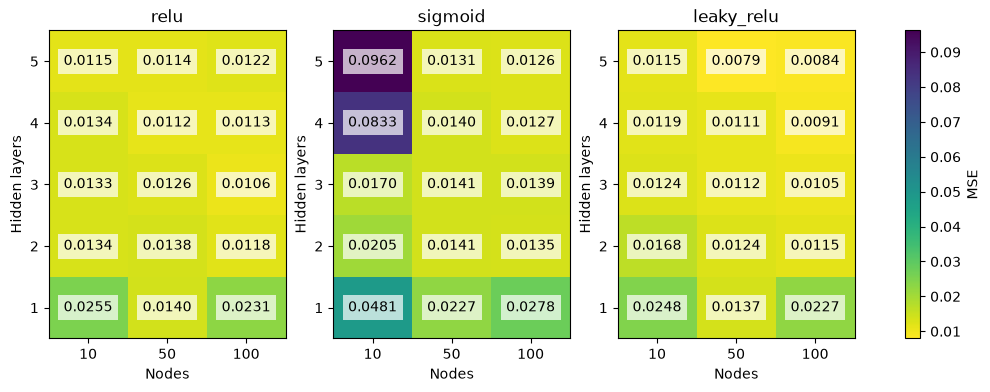

In [37]:
import numpy as np
train_scores = {key: history["train"][-1] for key, history in histories.items()}
matrices = [np.array([[train_scores[(act, layer, node)] for node in nodes ] for layer in hidden_layers])for act in act_func]
vmin = min(matrix.min() for matrix in matrices)
vmax = max(matrix.max() for matrix in matrices)
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 3, figsize = (13, 4))
for ax, act, matrix in zip(axes, act_func, matrices):
    image = ax.imshow(matrix, origin = "lower", aspect = "auto",cmap = "viridis_r",vmin=vmin, vmax=vmax)

    ax.set_xticks(range(len(nodes)), labels = nodes)
    ax.set_yticks(range(len(hidden_layers)), labels = hidden_layers)

    ax.set_xlabel("Nodes")
    ax.set_ylabel("Hidden layers")
    ax.set_title(act)

    for row in range(len(hidden_layers)):
                    for col in range(len(nodes)):
                            ax.text(col, row,
                                    f"{matrix[row, col]:.4f}", ha = "center", va = "center",
                                    color = "k", bbox = dict(facecolor="white", alpha = 0.7, edgecolor = "None"))

fig.colorbar(image, ax=axes, label = "MSE")
plt.show()  


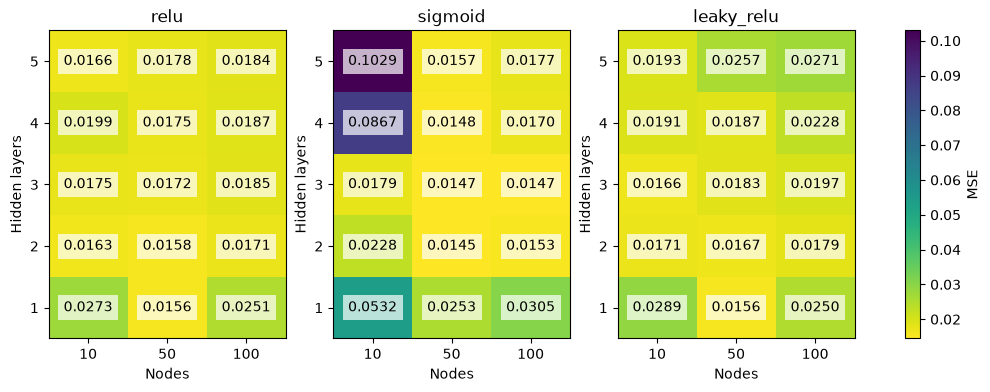

In [38]:
import numpy as np
matrices = [np.array([[scores[(act, layer, node)] for node in nodes ] for layer in hidden_layers])for act in act_func]
vmin = min(matrix.min() for matrix in matrices)
vmax = max(matrix.max() for matrix in matrices)
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 3, figsize = (13, 4))
for ax, act, matrix in zip(axes, act_func, matrices):
    image = ax.imshow(matrix, origin = "lower", aspect = "auto",cmap = "viridis_r",vmin=vmin, vmax=vmax)

    ax.set_xticks(range(len(nodes)), labels = nodes)
    ax.set_yticks(range(len(hidden_layers)), labels = hidden_layers)

    ax.set_xlabel("Nodes")
    ax.set_ylabel("Hidden layers")
    ax.set_title(act)

    for row in range(len(hidden_layers)):
                    for col in range(len(nodes)):
                            ax.text(col, row,
                                    f"{matrix[row, col]:.4f}", ha = "center", va = "center",
                                    color = "k", bbox = dict(facecolor="white", alpha = 0.7, edgecolor = "None"))

fig.colorbar(image, ax=axes, label = "MSE")
plt.show()  


**ReLU**
- Trening: MSE synker generelt med økende dybde. Effekten av flere noder varierer, men feilen synker ofte eller holder seg relativt stabil.
- Validering: MSE synker først med økende dybde, men øker ofte igjen i de dypere nettverkene. Effekten av bredde varierer. Noen tegn på overtilpasning.

**Sigmoid**
- Trening: Med 10 noder varierer MSE mye og er særlig høy ved fire og fem skjulte lag. Med 50 og 100 noder synker feilen med økende dybde.
- Validering: Følger stort sett treningsfeilen, men øker noe i de dypeste nettverkene med 50 og 100 noder. Høy feil på begge sett med 10 noder tyder heller på problemer med treningen.

**Leaky ReLU**
- Trening: MSE synker generelt med økende dybde og bredde, med enkelte unntak.
- Validering: Etter en innledende forbedring øker MSE generelt med dybden. I de dypere nettverkene øker den også med bredden. Dette gir tydelige tegn på overtilpasning.


Før vi konkluderer, må vi sjekke:
- Er dataoppdelingen, skaleringen og nettverkskoden riktig?
- Har vi testet nok ulike antall noder?
- Bør vi bruke Adam, og hvilken læringsrate?

In [41]:
best_key = min(scores, key=scores.get)
print("Best(activation function, nuber of nodes, Hidden layers):", best_key)
print("Validation MSE:", scores[best_key])

Best(activation function, nuber of nodes, Hidden layers): ('sigmoid', 2, 50)
Validation MSE: 0.011616914709760067


In [44]:
best_model = NeuralNetwork(layer_sizes=[X_train.shape[1], 50, 50, y_train.shape[1]],
                           activations=["sigmoid", "sigmoid", "identity"], cost = "mse", seed = 2026)
optimizer= Adam(learning_rate=0.001)
history = train(best_model, optimizer, X=X_train, y=y_train, epochs=epochs, batch_size=None, seed=2026, X_val=None, y_val=None)
test_mse = best_model.cost(X_test, y_test)
print(f"Test-MSE:{test_mse:.6f}")

Test-MSE:0.013188
